In [3]:
import pandas as pd
import numpy as np

df_telco = pd.read_csv('data/telco/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 1. Leerzeichen durch echte Fehlwerte (NaN) ersetzen
df_telco['TotalCharges'] = df_telco['TotalCharges'].replace(" ", np.nan)

# 2. Die Spalte in echte Zahlen umwandeln (float)
df_telco['TotalCharges'] = df_telco['TotalCharges'].astype(float)

# 3. Die wenigen fehlenden Werte (es sind nur 11 Stück) mit dem Median auffüllen
median_value = df_telco['TotalCharges'].median()
df_telco['TotalCharges'] = df_telco['TotalCharges'].fillna(median_value)

# 4. Die ID-Spalte brauchen wir nicht für das Modell, die schmeißen wir raus (Statistische Rechnen brauchen wir nicht)
df_telco = df_telco.drop(columns=['customerID'])

print("Bereinigung abgeschlossen!")
print("Datentyp von TotalCharges jetzt:", df_telco['TotalCharges'].dtype)
print("Fehlende Werte in TotalCharges:", df_telco['TotalCharges'].isnull().sum())

Bereinigung abgeschlossen!
Datentyp von TotalCharges jetzt: float64
Fehlende Werte in TotalCharges: 0


In [4]:
# 1. Zielvariable 'Churn' in 0 und 1 umwandeln
df_telco['Churn'] = df_telco['Churn'].map({'Yes': 1, 'No': 0})

# 2. Alle anderen Text-Spalten automatisch in 0 und 1 umwandeln
# drop_first=True verhindert die sogenannte "Multikollinearität" (spart eine Spalte pro Kategorie)
df_encoded = pd.get_dummies(df_telco, drop_first=True, dtype=int) #drop_first = löst eine tabelle

# Schauen wir uns an, wie die Daten jetzt aussehen
print("Form vor dem Encoding:", df_telco.shape)
print("Form nach dem Encoding:", df_encoded.shape) #shape = Dementation

Form vor dem Encoding: (7043, 20)
Form nach dem Encoding: (7043, 31)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Features (X) und Zielvariable (y) trennen
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 2. Train/Test Split (80% Training, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#Stratify= exact same ammount of y valus z.B. 30% Kundigung in test and Tranning Daten

# 3. Wichtig für Logistische Regression: Daten skalieren!
# Da "TotalCharges" in den Tausenden liegt und One-Hot-Spalten nur 0 oder 1 sind, bringen wir alles auf dieselbe Skala.
scaler = StandardScaler() #mittelwert geteillt durch Standerdabweichung dann wert ist immer -3 bis +3
# transform = (Wert - Mittelwert) / StandardabweichungVerwendet die gespeicherten Werte
# fit = Mittelwert + Standardabweichung -> beides gespeichert (hier wird auch gelernt) 
# fit_transform()Macht fit + transform in einem Schritt
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test)        

# 4. Modell erstellen und trainieren
model = LogisticRegression(max_iter=1000) #1000 weil optimale wert zu finden
model.fit(X_train_scaled, y_train)

print("Modell erfolgreich trainiert!")

Modell erfolgreich trainiert!


In [6]:
from sklearn.metrics import accuracy_score

# 1. Vorhersagen auf den Testdaten machen
y_pred = model.predict(X_test_scaled)

# 2. Accuracy = (Richtig erkante und nicht richtig erkannte kündiger)/Alle test person zusammen 
accuracy = accuracy_score(y_test, y_pred)

# 3. Ergebnis ausgeben (als Dezimalzahl und als Prozentwert)
print(f"Accuracy (Dezimal): {accuracy}")
print(f"Accuracy (Prozent): {accuracy:.2%}")

Accuracy (Dezimal): 0.8069552874378992
Accuracy (Prozent): 80.70%


In [7]:
from sklearn.metrics import precision_score

# Precision berechnen = True Positive / (True positive + false Positive) 
precision = precision_score(y_test, y_pred)

# Ergebnis ausgeben
print(f"Precision (Dezimal): {precision}")
print(f"Precision (Prozent): {precision:.2%}")

Precision (Dezimal): 0.6583850931677019
Precision (Prozent): 65.84%


In [8]:
from sklearn.metrics import recall_score

# Recall = Von allen Kunden, die in der Realität WIRKLICH gekündigt haben – wie viele hat das Modell tatsächlich entdeckt?“
# Recall berechnen
recall = recall_score(y_test, y_pred)

# Ergebnis ausgeben
print(f"Recall (Dezimal): {recall}")
print(f"Recall (Prozent): {recall:.2%}")

Recall (Dezimal): 0.5668449197860963
Recall (Prozent): 56.68%


In [9]:
from sklearn.metrics import f1_score

# F1-Score berechnen
f1 = f1_score(y_test, y_pred)

# Ergebnis ausgeben
print(f"F1-Score (Dezimal): {f1}")
print(f"F1-Score (Prozent): {f1:.2%}")

F1-Score (Dezimal): 0.6091954022988506
F1-Score (Prozent): 60.92%


In [10]:
from sklearn.metrics import roc_auc_score

# 1. Wahrscheinlichkeiten für die Klasse 1 (Kündigung) vorhersagen
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# 2. ROC-AUC berechnen
roc_auc = roc_auc_score(y_test, y_pred_proba)

# 3. Ergebnis ausgeben
print(f"ROC-AUC (Dezimal): {roc_auc}")
print(f"ROC-AUC (Prozent): {roc_auc:.2%}")

ROC-AUC (Dezimal): 0.8415846443979436
ROC-AUC (Prozent): 84.16%


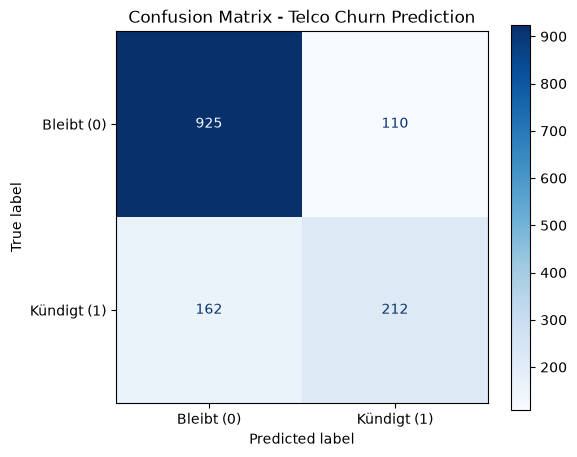

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Konfusionsmatrix berechnen
cm = confusion_matrix(y_test, y_pred)

# 2. Grafik erstellen und anzeigen
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=['Bleibt (0)', 'Kündigt (1)']
)

disp.plot(cmap='Blues', ax=ax, values_format='d')

plt.title('Confusion Matrix - Telco Churn Prediction')
plt.grid(False)  # Verhindert störende Gitterlinien über den Zahlen
plt.show()

In [12]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# 1. Random Forest Modell erstellen und trainieren
# Tipp: Beim Random Forest nutzen wir die unskalierten X_train Daten,
# da Entscheidungsbäume unempfindlich gegenüber unterschiedlichen Skalen sind.
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Vorhersagen machen
rf_pred = rf_model.predict(X_test)
rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# 3. Metriken für Random Forest berechnen
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_pred_proba)

# 4. Vergleichstabelle erstellen
results = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Logistic Regression': [accuracy, precision, recall, f1, roc_auc],
    'Random Forest': [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc]
})

# Prozentuale Formatierung für bessere Lesbarkeit
results['Logistic Regression'] = results['Logistic Regression'].map('{:.2%}'.format)
results['Random Forest'] = results['Random Forest'].map('{:.2%}'.format)

print("=== MODELLVERGLEICH ===")
print(results.to_string(index=False))

=== MODELLVERGLEICH ===
   Metrik Logistic Regression Random Forest
 Accuracy              80.70%        78.64%
Precision              65.84%        62.37%
   Recall              56.68%        49.20%
 F1-Score              60.92%        55.01%
  ROC-AUC              84.16%        82.51%
